# Filbin et al. 2018 — Pediatric H3-K27M Mutant Glioma (Brain)
## 01 · Preprocessing, integration, Gate 1
SmartSeq2 TPM (log1p). Malignant cells only. Data-driven sample threshold, Harmony on `sample`, UMAP, island removal, and the **Gate-1** mixing/continuity call judged on the regenerated embedding across an integration-strength (iLISI) sweep — never on a scalar alone.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# path logic: cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                   # Filbin2018_Brain-6
cat  = os.path.basename(os.path.dirname(os.getcwd()))  # Brain
pth  = os.path.join(*([os.pardir]*6))                  # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
# input leaf is the raw dataset dir (no '-6' suffix); outputs carry the '-6' suffix
raw = name.split('-')[0] if name.endswith('-6') else name          # Filbin2018_Brain
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw leaf: Data_'+raw)

dataset: Filbin2018_Brain-6 | category: Brain | raw leaf: Data_Filbin2018_Brain


In [ ]:
# load dataset -> malignant cells only. SmartSeq2 TPM: loader passes TPM through, applies log1p.
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| celltypes:', adata.obs.celltype.value_counts().to_dict())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TPM)' % adata.X.max())
adata

Loading ../../../../../../data/unzip/CCCA/Data_Filbin2018_Brain
Done.
full atlas: (2587, 23686) | celltypes: {'Malignant': 2259, 'Oligodendrocyte': 232, 'Macrophage': 96}
malignant: (2259, 23686) | samples: 6
expression: X max 12.36 (log1p of TPM)


AnnData object with n_obs × n_vars = 2259 × 23686
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'housekeeping_gene_expression', 'opc_variable', 'oc_like', 'ac_like', 'opc_like', 'celltype'
    uns: 'log1p'

In [ ]:
# per-sample malignant counts -> data-driven threshold (no anchor constant).
# rule: sort counts, take the largest multiplicative gap, cut at its geometric mean.
# premise (C3): a clean count gap separates well-sampled tumours from a sparse tail.
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('adjacent ratios:', np.round(ratios, 2))
print(f'largest gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}); threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')
adata

sorted per-sample counts: {'MUV05': np.int64(667), 'BCH869': np.int64(489), 'BCH836': np.int64(438), 'MUV10': np.int64(283), 'BCH1126': np.int64(241), 'MUV01': np.int64(141)}
adjacent ratios: [1.36 1.12 1.55 1.17 1.71]
largest gap 241 -> 141 (ratio 1.71); threshold = 184
kept 5/6 samples -> 2118 cells


AnnData object with n_obs × n_vars = 2118 × 23686
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'housekeeping_gene_expression', 'opc_variable', 'oc_like', 'ac_like', 'opc_like', 'celltype'
    uns: 'log1p'

In [ ]:
# filter genes -> overdispersed selection (scFates GAM) -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2))
# scree elbow sits low (PC1 dominates); the eval audit flags a low elbow as under-powering the
# manifold into a patient-segregated read. Bound to the SmartSeq2/10x precedent (Kurten 20, Puram 40).
NPCS = 20
print('n_pcs =', NPCS, '(scree elbow rejected as under-powering; bounded to precedent)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3583 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3583
PC variance% (1-12): [5.1  2.43 1.68 1.46 1.31 0.51 0.45 0.35 0.33 0.29 0.26 0.24]
n_pcs = 20 (scree elbow rejected as under-powering; bounded to precedent)


In [ ]:
# integrate samples with Harmony -> choose theta by per-neighbourhood mixing (iLISI), not a scalar.
def _ilisi(rep, labels, k=90):
    k = min(k, rep.shape[0]-1)
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:, :NPCS], adata.obs['sample'].values))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = np.median(_ilisi(adata.obsm['X_pca_harmony'][:, :NPCS], adata.obs['sample'].values))
print(f'iLISI median (of {nsamp} samples): pre-Harmony {il_pre:.2f} | sweep',
      {k: round(v, 2) for k, v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing rises monotonically 2.8->3.66, no collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

iLISI median (of 5 samples): pre-Harmony 1.00 | sweep {2: np.float64(2.8), 5: np.float64(3.49), 10: np.float64(3.66)}
selected theta = 10 (mixing rises monotonically 2.8->3.66, no collapse)


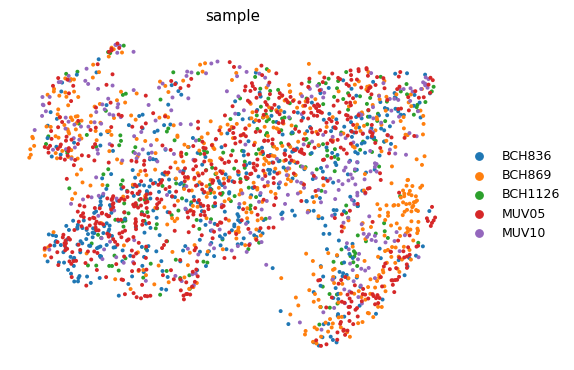

In [ ]:
# Gate-1 evidence #1 — the regenerated embedding coloured by sample (judged on the embedding itself).
sc.pl.umap(adata, color='sample', size=40, frameon=False)

In [ ]:
# remove detached islands: UMAP radius-graph (6x median NN), keep the largest component.
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:, 1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print(f'radius-graph components: {ncomp}; largest = {int((lab==main).sum())} cells; removed {int((lab!=main).sum())}')
adata = adata[lab == main].copy()
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
print('kNN connectivity components:', ncc, '(1 = continuous)')

radius-graph components: 1; largest = 2118 cells; removed 0
kNN connectivity components: 1 (1 = continuous)


lobe sizes    : {'0': 451, '1': 367, '2': 251, '3': 331, '4': 718}
cycling / lobe: {'0': 0.03, '1': 0.11, '2': 0.96, '3': 0.02, '4': 0.1}
overall cycling fraction: 0.176


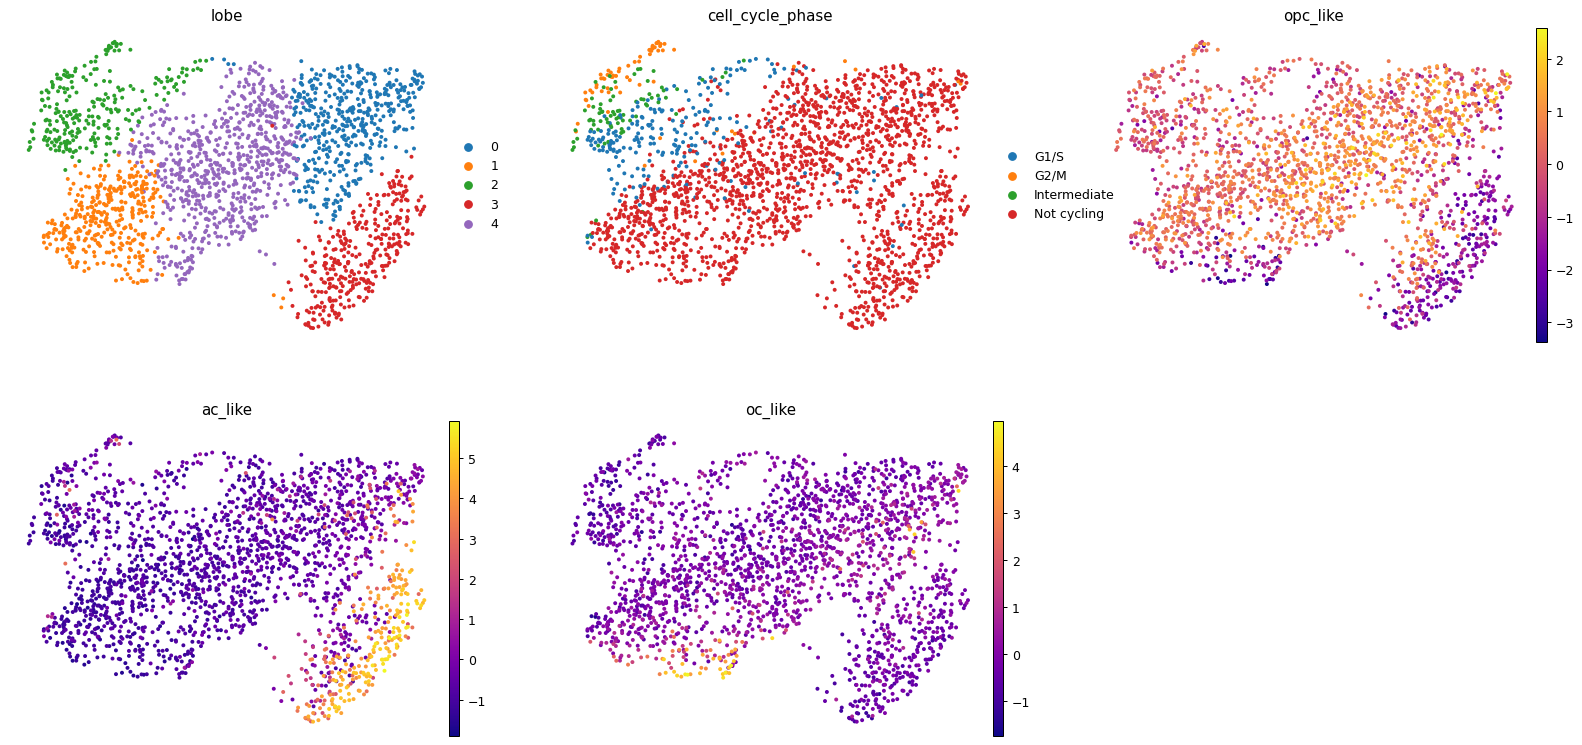

In [ ]:
# Gate-1 evidence #2 — sub-region biology BEFORE the GO (Kurten lobe-identity fork).
# Filbin published per-cell lineage scores (OPC/AC/OC-like) + cell cycle: read them directly.
for c in ['opc_like','ac_like','oc_like','g1s_score','g2m_score']:
    adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce')
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes    :', adata.obs['lobe'].value_counts().sort_index().to_dict())
print('cycling / lobe:', cyc.round(2).to_dict())
print('overall cycling fraction:', round(adata.obs['cycling'].mean(), 3))
sc.pl.umap(adata, color=['lobe','cell_cycle_phase','opc_like','ac_like','oc_like'],
           size=40, frameon=False, cmap='plasma', ncols=3)

In [ ]:
# Gate-1 evidence #3 — the published glial hierarchy IS the manifold structure:
# a cycling OPC-like progenitor pool differentiating toward AC-like and OC-like states.
# These sub-regions are lineage states of ONE continuous developmental hierarchy, not separate
# tumours or a detachable confound -> keep the whole manifold. (Cell-cycle orthogonality to the
# embryonic modules is confirmed quantitatively in 02.)
print('samples per lobe (integration within each sub-region):')
print(pd.crosstab(adata.obs['lobe'], adata.obs['sample']))
print()
print(f'Gate 1: {nsamp} samples share ONE continuous manifold (single kNN component);')
print(f'  per-neighbourhood iLISI rises {il_pre:.2f} -> {sweep[10]:.2f} of {nsamp} under Harmony;')
print('  sub-regions are OPC/AC/OC lineage states of one hierarchy, not per-sample islands.')
print('  Gate 1: mixed + continuous -> GO')

samples per lobe (integration within each sub-region):
sample  BCH836  BCH869  BCH1126  MUV05  MUV10
lobe                                         
0           97      69       60    135     90
1          123      32       39    152     21
2           28      80       22     63     58
3           48     140       24     83     36
4          142     168       96    234     78

Gate 1: 5 samples share ONE continuous manifold (single kNN component);
  per-neighbourhood iLISI rises 1.00 -> 3.66 of 5 under Harmony;
  sub-regions are OPC/AC/OC lineage states of one hierarchy, not per-sample islands.
  Gate 1: mixed + continuous -> GO


In [ ]:
# house orientation: rigid rotation onto the major axis, developmental origin on the LEFT.
# origin = cycling OPC-like progenitor (Filbin hierarchy root); distances preserved (X_umap_lin).
opc = adata.obs['opc_like'].values; g2m = adata.obs['g2m_score'].values
origin = (opc - opc.min()) + (g2m - g2m.min())           # progenitor-ness weight
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0, 1], vt[0, 0])
Rm = np.array([[np.cos(-th), -np.sin(-th)], [np.sin(-th), np.cos(-th)]])
xyr = c @ Rm.T
if np.average(xyr[:, 0], weights=(origin - origin.min() + 1e-9)) > 0:
    xyr[:, 0] = -xyr[:, 0]                                # progenitor pole -> left
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th):+.1f}deg, progenitor pole on left -> X_umap_lin')

manifold aspect (max/min std): 1.83
house orientation: rigid rotation +179.6deg, progenitor pole on left -> X_umap_lin


In [ ]:
# tidy obs dtypes -> save processed manifold
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum() and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2118, 21106)


saved samples.pdf | cells: 2118


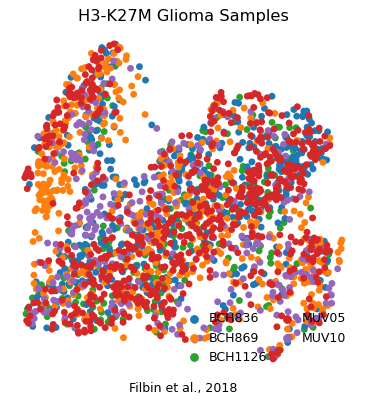

In [ ]:
# deliverable: samples.pdf — Puram branching style (square panel, raw UMAP, inverted axes).
# colour = sample; intermixing across the manifold is the Gate-1 integration evidence.
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='sample', size=120, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='lower right', columnspacing=.5,
          handletextpad=.25)
ax.set_title('H3-K27M Glioma Samples', size=13)
ax.text(.5, -.05, 'Filbin et al., 2018', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])